# Agent的基本使用

## 1、Agent中模型的传入方式

### 1.1 传入字符串

In [2]:
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
from openai.types.realtime import response_mcp_call_arguments_delta

load_dotenv(override=True)
agent = create_agent(
    model="deepseek:deepseek-v4-flash" # 调用的是ChatDeepseek()


)

print(type(agent))

<class 'langgraph.graph.state.CompiledStateGraph'>


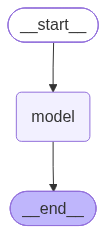

In [3]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### 1.2 传入模型实例

In [6]:
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.chat_models import init_chat_model
load_dotenv(override=True)

model = init_chat_model(
    model = "deepseek:deepseek-v4-flash"
)

agent = create_agent(
    model = model # 调用的是ChatDeepseek()


)

print(type(agent))

<class 'langgraph.graph.state.CompiledStateGraph'>


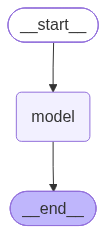

In [7]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

## 2、如何调用agent

举例1：

In [3]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from dotenv import load_dotenv
from rich import print as rprint
import os

MODEL_NAME = "deepseek-flash"

# 从.env文件中加载环境变量
load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2.模型的初始化
model = init_chat_model(
    model="deepseek:deepseek-chat",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,

)

agent = create_agent(
    model=model
)


# 调用行为
# response = agent.invoke({
#     "messages":[
#         {"role":"user","content":"你好"}
#     ]
# })

response = agent.invoke({
    "messages":[
        "你好"
    ]
})
rprint(response)

{
    'messages': [
        HumanMessage(
            content='你好',
            additional_kwargs={},
            response_metadata={},
            id='6e339e4b-219c-4db1-8959-30c546f62b34'
        ),
        AIMessage(
            content='你好！很高兴见到你，有什么我可以帮你的吗？',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 12,
                    'prompt_tokens': 5,
                    'total_tokens': 17,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 5
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '13b780cf-b170-487d-8ced-1e96c5c4dbbd',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a17719-2d1a-7593-a922-04685181da7d-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 5,
                'output_tokens': 12,
                'total_tokens': 17,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        )
    ]
}

举例2：

In [5]:
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from dotenv import load_dotenv
from rich import print as rprint
import os

MODEL_NAME = "deepseek-flash"

# 从.env文件中加载环境变量
load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2.模型的初始化
model = init_chat_model(
    model="deepseek:deepseek-chat",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,

)

agent = create_agent(
    model=model
)


# 调用行为
response = agent.invoke({ # 调用agent的时候invoke里面是以字典的方式传进来
    "messages":[
        {"role":"system","content":"你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题"},
        {"role":"user","content":"100 + 20 * 3 =?"}
    ]
})


rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个精通数学的老师，擅长以通俗易懂的方式讲解数学问题',
            additional_kwargs={},
            response_metadata={},
            id='72b277a0-a83d-4e73-8caa-9b4218e6e9f3'
        ),
        HumanMessage(
            content='100 + 20 * 3 =?',
            additional_kwargs={},
            response_metadata={},
            id='7bd62054-405a-41c2-8c6a-fd467966232c'
        ),
        AIMessage(
            content='好的，我们一起来看这个算式：**100 + 20 × 3 = 
?**\n\n这里有一个关键点——**运算顺序**。\n\n我们在做混合运算时，要记住口诀：**先乘除，后加减**。\n\n所以这个式子里的
乘法要先算：\n\n1. 先算 **20 × 3 = 60**\n2. 再算 **100 + 60 = 160**\n\n所以：\n\n**100 + 20 × 3 = 
160**\n\n你可以把它想象成：先买20元的东西买3份，一共60元，再加上原来的100元，总共160元。\n\n最终答案是：**160** 
✅',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 132,
                    'prompt_tokens': 28,
                    'total_tokens': 160,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 28
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '0755e79b-3e40-4e83-acdc-12038df127ec',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1771e-0e52-7dd2-9ca7-a81e5c8df51f-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 28,
                'output_tokens': 132,
                'total_tokens': 160,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        )
    ]
}

## 3、如何绑定工具，并调用工具

### 举例1：绑定一个自定义工具

In [8]:
from langchain.tools import tool
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from dotenv import load_dotenv
from rich import print as rprint
import os

MODEL_NAME = "deepseek-flash"

# 从.env文件中加载环境变量
load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2.模型的初始化
model = init_chat_model(
    model="deepseek:deepseek-chat",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,

)

# 定义一个工具
@tool(parse_docstring=True)
def get_weather(city : str):
    """
    查询天气的工具

    Args:
        city : 城市名称
    """
    return f"{city}的天气是晴天,温度是15摄氏度"

agent = create_agent(
    model = model,
    tools = [get_weather]
)

response = agent.invoke({
    "messages" : [
        {"role":"system","content":"你是一个查询天气的助手，根据用户的提问查询天气。如果问题跟天气无关，你可以说我不清楚这个问题的答案"},
        {"role":"user","content":"北京的天气如何?"}
    ]
})

rprint(response)

{
    'messages': [
        SystemMessage(
            content='你是一个查询天气的助手，根据用户的提问查询天气。如果问题跟天气无关，你可以说我不清楚这个问题的
答案',
            additional_kwargs={},
            response_metadata={},
            id='c26c16a9-7ba7-4078-b3e2-810990277b11'
        ),
        HumanMessage(
            content='北京的天气如何?',
            additional_kwargs={},
            response_metadata={},
            id='f573b764-e727-4107-b2c4-8ed8cb965dfe'
        ),
        AIMessage(
            content='',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 38,
                    'prompt_tokens': 299,
                    'total_tokens': 337,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 0,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 0,
                    'prompt_cache_miss_tokens': 299
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '45008c61-2f3e-477a-b8c1-f7a2bbd1acf1',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a17729-46ce-7e20-aeac-5848a9e3c8a9-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '北京'},
                    'id': 'call_00_BuZBoinVHNZOr3IWz3OL1452',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 299,
                'output_tokens': 38,
                'total_tokens': 337,
                'input_token_details': {'cache_read': 0},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='北京的天气是晴天,温度是15摄氏度',
            name='get_weather',
            id='b5acb28b-d0f0-46a4-84a6-9429ac1606ef',
            tool_call_id='call_00_BuZBoinVHNZOr3IWz3OL1452'
        ),
        AIMessage(
            content='北京现在是晴天，气温15摄氏度，天气不错，适合外出活动。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 15,
                    'prompt_tokens': 358,
                    'total_tokens': 373,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 128,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 230
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '432dee1b-5c4d-488c-8c13-f072fdd1057a',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a17729-4acf-78a0-a0e3-498c1ecaf8f9-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 358,
                'output_tokens': 15,
                'total_tokens': 373,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {}
            }
        )
    ]
}

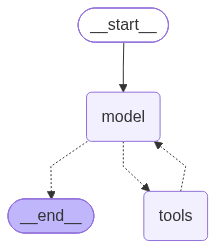

In [9]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

### 举例2：调用langchain内置的工具

In [11]:
from langchain.tools import tool
from langchain_tavily import TavilySearch
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from dotenv import load_dotenv
from rich import print as rprint
import os

MODEL_NAME = "deepseek-flash"

# 从.env文件中加载环境变量
load_dotenv(override=True)

DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")

# 2.模型的初始化
model = init_chat_model(
    model="deepseek:deepseek-chat",
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,

)

# 定义一个工具
web_search = TavilySearch(
    max_results=2,
    tavily_api_key=os.getenv("TAVILY_API_KEY")


)
# 使用内置的工具
agent = create_agent(
    model = model,
    tools = [web_search]

)

response = agent.invoke({
    "messages" : [
        {"role":"user","content":"Please help me check who won the 2025 Ballon d'Or?"}
    ]
})

rprint(response)

{
    'messages': [
        HumanMessage(
            content="Please help me check who won the 2025 Ballon d'Or?",
            additional_kwargs={},
            response_metadata={},
            id='0a431bc7-4887-4ee1-a055-88d23ca3838d'
        ),
        AIMessage(
            content="I'll look that up for you.",
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 110,
                    'prompt_tokens': 1816,
                    'total_tokens': 1926,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 1664,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 1664,
                    'prompt_cache_miss_tokens': 152
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '937717bb-96b2-483e-a117-b670c5bfaf26',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a17747-8c3b-7070-86d6-3a646be1869d-0',
            tool_calls=[
                {
                    'name': 'tavily_search',
                    'args': {'query': "2025 Ballon d'Or winner", 'topic': 'news'},
                    'id': 'call_00_VJMj6OBtN2yd6cbLctWu3093',
                    'type': 'tool_call'
                },
                {
                    'name': 'tavily_search',
                    'args': {'query': "Ballon d'Or 2025 ceremony results winner men's award"},
                    'id': 'call_01_f6CNlBfnnCFqetDXq1LG1315',
                    'type': 'tool_call'
                }
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 1816,
                'output_tokens': 110,
                'total_tokens': 1926,
                'input_token_details': {'cache_read': 1664},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='{"query": "2025 Ballon d\'Or winner", "follow_up_questions": null, "answer": null, "images": 
[], "results": [{"url": 
"https://m.economictimes.com/news/new-updates/who-won-the-ballon-dor-2026-winner-list-mens-ranking-and-full-list-of
-contenders-harry-kane-lamine-yamal-kylian-mbappe-erling-haaland-lionel-messi/articleshow/135201605.cms", "title": 
"Who won the Ballon d\'Or 2026? Winner, men\'s ranking and full list of contenders - The Economic Times", 
"content": "## Who won the Ballon d\'Or in 2025?\\n\\nOusmane Dembele won the men\'s Ballon d\'Or in 2025 after an 
outstanding season with Paris Saint-Germain. Aitana Bonmati won the women\'s award that year. Dembele is among the 
nominees again in 2026, but he faces competition from several high-profile players hoping to claim the trophy this 
time.  \\n  \\n\\n## When will the Ballon d\'Or 2026 winner be announced in India? [...] Ousmane Dembele won the 
men\'s Ballon d\'Or in 2025, while Aitana Bonmati won the women\'s award. [...] The winner of the men\'s Ballon 
d\'Or 2026 is yet to be confirmed officially before the ceremony. Football fans will have to wait for the 
announcement to discover who will succeed Ousmane Dembele, who won the men\'s award in 2025. Several leading 
footballers are in contention for the honour, including Harry Kane, Lamine Yamal, Kylian Mbappe, Erling Haaland and
Lionel Messi. Their performances during the eligible period have made them part of the conversation around this 
year\'s award. However,", "score": 0.9255605, "raw_content": null, "published_date": "Mon, 26 Oct 2026 03:00:00 
GMT", "id": "dae235-00"}, {"url": "ht

### 举例3：绑定多个工具，并调用

In [18]:
from langchain.tools import tool
from langchain_tavily import TavilySearch
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from dotenv import load_dotenv
from rich import print as rprint
import os

# 从.env文件中加载环境变量
load_dotenv(override=True)


@tool(parse_docstring=True)
def get_weather(city: str):
    """
    天气查询工具

    Args:
        city: 城市名称
    """
    return f"{city}今天天气挺好"

@tool(parse_docstring=True)
def get_news():
    """
    新闻查询工具
    """
    return "近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧手机成“香饽饽”。"

agent = create_agent(
    model,
tools=[get_weather, get_news]
)
response = agent.invoke({
"messages": ["你好，杭州今天的天气如何？今天有哪些新闻？"]
})
rprint(response)

{
    'messages': [
        HumanMessage(
            content='你好，杭州今天的天气如何？今天有哪些新闻？',
            additional_kwargs={},
            response_metadata={},
            id='f4e1dd4c-a667-4e57-b1b8-0c73488fc75f'
        ),
        AIMessage(
            content='我来帮你查询杭州的天气和今天的新闻。',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 60,
                    'prompt_tokens': 310,
                    'total_tokens': 370,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 128,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 128,
                    'prompt_cache_miss_tokens': 182
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': 'b8a9787b-d30e-43cf-be93-656c219e5c8f',
                'finish_reason': 'tool_calls',
                'logprobs': None
            },
            id='lc_run--01a1774c-5e03-77e0-a90f-d565a2033c68-0',
            tool_calls=[
                {
                    'name': 'get_weather',
                    'args': {'city': '杭州'},
                    'id': 'call_00_6ZZC5BXY56XGXf46izo86670',
                    'type': 'tool_call'
                },
                {'name': 'get_news', 'args': {}, 'id': 'call_01_gvhX2lQs1WeUiyEfWlOw1812', 'type': 'tool_call'}
            ],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 310,
                'output_tokens': 60,
                'total_tokens': 370,
                'input_token_details': {'cache_read': 128},
                'output_token_details': {}
            }
        ),
        ToolMessage(
            content='杭州今天天气挺好',
            name='get_weather',
            id='9e78f8d6-5fbb-4fe5-854d-93d2692cd989',
            tool_call_id='call_00_6ZZC5BXY56XGXf46izo86670'
        ),
        ToolMessage(
            content='近期，受全球储蓄芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍
上涨，旧手机成“香饽饽”。',
            name='get_news',
            id='680a6b5a-ec76-4a9d-ac5d-f19261f30936',
            tool_call_id='call_01_gvhX2lQs1WeUiyEfWlOw1812'
        ),
        AIMessage(
            content='你好！查询结果如下：\n\n**🌤️ 杭州今日天气**\n杭州今天天气挺好，适合外出活动～\n\n**📰 
今日新闻**\n近期，受全球存储芯片短缺等多重因素影响，多地回收商称废旧手机回收市场迎来“火热潮”，回收价格普遍上涨，旧
手机成了“香饽饽”。\n\n如果你需要更具体的天气信息（如温度、湿度）或想深入了解某条新闻，可以再告诉我～',
            additional_kwargs={'refusal': None},
            response_metadata={
                'token_usage': {
                    'completion_tokens': 94,
                    'prompt_tokens': 434,
                    'total_tokens': 528,
                    'completion_tokens_details': None,
                    'prompt_tokens_details': {
                        'audio_tokens': None,
                        'cache_write_tokens': None,
                        'cached_tokens': 256,
                        'image_tokens': None,
                        'text_tokens': None
                    },
                    'prompt_cache_hit_tokens': 256,
                    'prompt_cache_miss_tokens': 178
                },
                'model_provider': 'deepseek',
                'model_name': 'deepseek-flash',
                'system_fingerprint': 'e72d3c7f663d3e1383b00b3884cb4501',
                'id': '04695eb5-0a45-4866-b4aa-732a907439a6',
                'finish_reason': 'stop',
                'logprobs': None
            },
            id='lc_run--01a1774c-6176-7460-89de-207d8c9d6534-0',
            tool_calls=[],
            invalid_tool_calls=[],
            usage_metadata={
                'input_tokens': 434,
    